In [76]:
from upsetplot import from_contents
from upsetplot import UpSet
import pandas as pd

In [77]:
snapshot_1 = pd.read_csv("../data/interim/queries-snapshot-1.tsv", sep="\t", names=["query", "query_id"])
snapshot_2 = pd.read_csv("../data/interim/queries-snapshot-2.tsv", sep="\t", names=["query", "query_id"])
snapshot_3 = pd.read_csv("../data/interim/queries-snapshot-3.tsv", sep="\t", names=["query", "query_id"])
snapshot_test = pd.read_csv("../data/interim/queries-snapshot-test.tsv", sep="\t", names=["query", "query_id"])

In [78]:
def prepare_data(snapshots):
    names = {
        "test" : "Snapshot Test",
        1: "Snapshot 03-05",
        2: "Snapshot 06-08",
        3: "Snapshot 09-11"
    }
    data = {}
    for i, d in enumerate(snapshots):
        queries = d["query_id"].unique().tolist()
        data[names[list(names.keys())[i]]] = queries
    return data

In [79]:
data = prepare_data([snapshot_test, snapshot_1, snapshot_2, snapshot_3])

/workspaces/conf26-longeval-sci/.venv/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/workspaces/conf26-longeval-sci/.venv/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

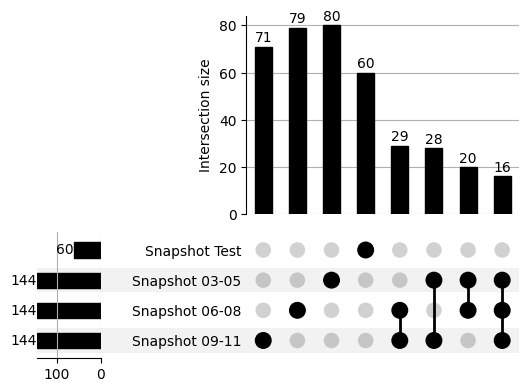

In [80]:
mysets = from_contents(data)
ax_dict = UpSet(mysets, sort_categories_by="-input",subset_size="count", show_counts=True).plot()

## Remove additional queries

In [73]:
df = pd.read_csv("../data/interim/candidate_queries.tsv", sep="\t")
rejected = pd.read_csv("../data/interim/LongEval-Sci Query Candidates - candidate_queries.tsv", sep="\t")
rejected = set(rejected[rejected["REMOVE (Jüri)"] =="x"]["query_id"].to_list())
df = df[~df["query_id"].isin(rejected)]

In [ ]:
# Remove from snapshot 3
# df[(df["snapshot-3"]>60) & (df["snapshot-2"]<30) & (df["snapshot-1"]<30)].sort_values("len").to_csv("../data/interim/remove-from-snapshot-3.tsv", sep="\t", index=False)

In [ ]:
# # Select test queries from snapshot 1
# df[(df["snapshot-1"]>30) & (df["snapshot-2"]<30) & (df["snapshot-3"]<30)].sample(103, random_state=42).to_csv("../data/interim/test-queries.tsv", sep="\t", index=False)